In [1]:
import sys

sys.path.append("../src")
import torch
from datasets.bird_call_photo_latent_mix import BirdCallPhotoLatentMix
from models.diffusion import Diffusion
from models.vae import VAE
from processing.audio import log_mel_to_waveform
from IPython.display import Audio, display
from torchvision.transforms.functional import to_pil_image

In [2]:
AUDIO_DATASET_PATH = "../data/iNaturalistLatentsAudio"
PHOTO_DATASET_PATH = "../data/iNaturalistLatentsPhoto"
AUDIO_VAE_CHECKPOINT_PATH = (
    "../models/audio_vae/1784428657621265322/photo_vae_final.tar"
)
PHOTO_VAE_CHECKPOINT_PATH = (
    "../models/photo_vae/1784428654983751466/photo_vae_final.tar"
)
PHOTO_DIFFUSION_CHECKPOINT_PATH = "../models/conditional_photo_diffusion/1784866012799505633/conditional_photo_diffusion_final.tar"

diffusion_checkpoint = torch.load(PHOTO_DIFFUSION_CHECKPOINT_PATH, weights_only=False)
vae_checkpoint = torch.load(PHOTO_VAE_CHECKPOINT_PATH, weights_only=False)

diffusion_parameters = diffusion_checkpoint['model_parameters']
vae_parameters = vae_checkpoint['model_parameters']
train_parameters = diffusion_checkpoint['train_parameters']
train_parameters.device = "cuda:0"

In [3]:
train_dataset = BirdCallPhotoLatentMix(
    AUDIO_DATASET_PATH,
    PHOTO_DATASET_PATH,
    AUDIO_VAE_CHECKPOINT_PATH,
    PHOTO_VAE_CHECKPOINT_PATH,
    split="train",
    audio_first=False,
    num_pairs_per_species=500,
)
val_dataset = BirdCallPhotoLatentMix(
    AUDIO_DATASET_PATH,
    PHOTO_DATASET_PATH,
    AUDIO_VAE_CHECKPOINT_PATH,
    PHOTO_VAE_CHECKPOINT_PATH,
    split="val",
    audio_first=False,
    num_pairs_per_species=500,
)

In [4]:
diffusion = Diffusion(diffusion_parameters)
diffusion.load_state_dict(diffusion_checkpoint['model_state_dict'])
diffusion = diffusion.to(train_parameters.device)
diffusion.eval()

Diffusion(
  (initial_conv): Conv2d(4, 32, kernel_size=(1, 1), stride=(1, 1))
  (conditioning_embedding): Sequential(
    (0): Conv2d(4, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): SiLU()
    (2): AdaptiveAvgPool2d(output_size=(16, 16))
  )
  (noise_embedding): SinusoidalEmbedding()
  (upsample): Upsample(size=(16, 16), mode='nearest')
  (down1): DownBlock(
    (blocks): ModuleList(
      (0): ResidualBlock(
        (conv1): Conv2d(96, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
        (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
        (act1): SiLU()
        (act2): SiLU()
        (norm1): GroupNorm(8, 96, eps=1e-05, affine=True)
        (norm2): GroupNorm(8, 32, eps=1e-05, affine=True)
        (residual): Conv2d(96, 32, kernel_size=(1, 1), stride=(1, 1))
      )
      (1): ResidualBlock(
        (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
        (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1

In [5]:
vae = VAE(vae_parameters)
vae.load_state_dict(vae_checkpoint['model_state_dict'])
vae = vae.to(train_parameters.device)
vae.eval()

VAE(
  (encoder): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): ResidualBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (act1): SiLU()
      (act2): SiLU()
      (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
      (norm2): GroupNorm(8, 64, eps=1e-05, affine=True)
      (residual): Identity()
    )
    (2): ResidualBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (act1): SiLU()
      (act2): SiLU()
      (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
      (norm2): GroupNorm(8, 64, eps=1e-05, affine=True)
      (residual): Identity()
    )
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (4): ResidualBlock(
      (conv1): Conv2d(128, 128, kernel_size=(3, 3), st

Abert's Towhee


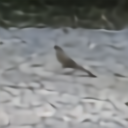

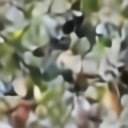

In [6]:
latent_1, latent_2, species = train_dataset[0]
latent_1 = latent_1.to(train_parameters.device)
latent_2 = latent_2.to(train_parameters.device)

samples = diffusion.sample(diffusion, latent_2.unsqueeze(0), dif_steps=1000, device=train_parameters.device)

print(species)

with torch.no_grad():
    photo_example_of_original = vae.decode(latent_1.unsqueeze(0).to(train_parameters.device))
    photo_generated = vae.decode(samples[0].to(train_parameters.device))

display(to_pil_image((photo_example_of_original[0] * 255).to(torch.uint8)))
display(to_pil_image((photo_generated[0] * 255).to(torch.uint8)))

Acadian Flycatcher


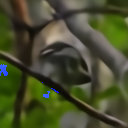

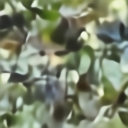

In [7]:
latent_1, latent_2, species = train_dataset[100]
latent_1 = latent_1.to(train_parameters.device)
latent_2 = latent_2.to(train_parameters.device)

samples = diffusion.sample(diffusion, latent_2.unsqueeze(0), device=train_parameters.device)

print(species)

with torch.no_grad():
    photo_example_of_original = vae.decode(latent_1.unsqueeze(0).to(train_parameters.device))
    photo_generated = vae.decode(samples[0].to(train_parameters.device))

display(to_pil_image((photo_example_of_original[0] * 255).to(torch.uint8)))
display(to_pil_image((photo_generated[0] * 255).to(torch.uint8)))

Acorn Woodpecker


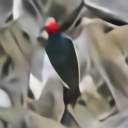

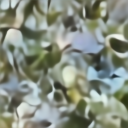

In [8]:
latent_1, latent_2, species = train_dataset[200]
latent_1 = latent_1.to(train_parameters.device)
latent_2 = latent_2.to(train_parameters.device)

samples = diffusion.sample(diffusion, latent_2.unsqueeze(0), device=train_parameters.device)

print(species)

with torch.no_grad():
    photo_example_of_original = vae.decode(latent_1.unsqueeze(0).to(train_parameters.device))
    photo_generated = vae.decode(samples[0].to(train_parameters.device))

display(to_pil_image((photo_example_of_original[0] * 255).to(torch.uint8)))
display(to_pil_image((photo_generated[0] * 255).to(torch.uint8)))